# Random Forest: modelo base y ajuste de hiperparámetros
**Proyecto de Ciencia de Datos — Grupo 10**  
Isaias Carte y Rodrigo Ramirez

Se ajusta un Random Forest base con los mismos seis predictores y **exactamente los índices de entrenamiento/prueba guardados para la regresión logística**. No se genera otra partición, no se incorpora país y no se cambian hiperparámetros tras observar el test. Las métricas son sin ponderación muestral. La comparación con regresión logística es descriptiva y no determina todavía qué modelo elegir.

La segunda parte realiza una búsqueda moderada exclusivamente dentro de entrenamiento. Se selecciona por ROC-AUC de validación cruzada y se evalúa una sola vez la configuración seleccionada en el test, sin seleccionar un ganador final entre familias de modelos.

## 1. Carga y comprobación de insumos
Se utiliza `data/processed/findex_lac_clean.csv`. Su huella debe coincidir con la registrada para la regresión logística, de modo que los índices guardados identifiquen las mismas filas. El objetivo es `account_fin`: 0 = sin cuenta y 1 = con cuenta. Predictores: edad, sexo, educación, quintil de ingreso, participación laboral y teléfono móvil. No se modifica la base validada ni se eliminan nuevas personas.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, roc_curve
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path(".") if Path("src/evaluation.py").is_file() else Path("..")
assert (ROOT / "src/evaluation.py").is_file(), "Ejecutar desde la raíz o notebooks/."
sys.path.insert(0, str(ROOT))
from src.data_processing import VALID_CODES
from src.evaluation import evaluate_binary_classifier

DATA_PATH = ROOT / "data/processed/findex_lac_clean.csv"
SPLIT_PATH = ROOT / "outputs/tables/model_split_indices.csv"
METRICS = ROOT / "outputs/metrics"
FIGURES = ROOT / "outputs/figures"
MODELS = ROOT / "models"
for directory in [METRICS, FIGURES, MODELS]:
    directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 100})

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

input_paths = [DATA_PATH, SPLIT_PATH,
               METRICS / "logistic_run_info.json", METRICS / "logistic_metrics.csv",
               METRICS / "logistic_model_comparison.csv", METRICS / "logistic_test_predictions.csv",
               METRICS / "logistic_sensitivity_specificity.csv"]
input_hashes = {str(path.relative_to(ROOT)): sha256(path) for path in input_paths}
logistic_info = json.loads((METRICS / "logistic_run_info.json").read_text(encoding="utf-8"))
assert sha256(DATA_PATH) == logistic_info["dataset_sha256"]
assert sha256(SPLIT_PATH) == logistic_info["artifact_sha256"]["outputs/tables/model_split_indices.csv"]
predictors = ["age", "female", "educ", "inc_q", "emp_in", "mobileowner"]
assert predictors == logistic_info["predictors"]
data = pd.read_csv(DATA_PATH)
assert not data[["account_fin"] + predictors].isna().any().any()
assert np.isfinite(data[["account_fin"] + predictors].to_numpy()).all()
for column, values in VALID_CODES.items():
    assert set(data[column].unique()) <= values
assert set(data.account_fin.unique()) == {0, 1}
assert data.age.between(15, 99).all() and data.age.eq(data.age.round()).all()
X = data[predictors].copy()
y = data.account_fin.copy()
print(f"Base: {len(data):,} personas. X: {X.shape}. Objetivo: account_fin.")

Base: 18,927 personas. X: (18927, 6). Objetivo: account_fin.


## 2. Recuperar exactamente el train/test existente
Se leen los índices base cero de `model_split_indices.csv` y se respeta `orden_en_particion`. Se valida cobertura completa, ausencia de duplicados, separación de personas y coincidencia con las observaciones de prueba evaluadas por la regresión logística. Aquí **no se llama a train_test_split**.

In [2]:
saved_split = pd.read_csv(SPLIT_PATH)
assert set(saved_split.columns) == {"fila_dataset", "particion", "orden_en_particion"}
assert not saved_split.isna().any().any()
assert set(saved_split.particion) == {"entrenamiento", "prueba"}
assert saved_split.fila_dataset.is_unique
assert set(saved_split.fila_dataset) == set(data.index)
for column in ["fila_dataset", "orden_en_particion"]:
    assert saved_split[column].eq(saved_split[column].astype(int)).all()
indices = {}
for partition in ["entrenamiento", "prueba"]:
    rows = saved_split.loc[saved_split.particion.eq(partition)].sort_values("orden_en_particion")
    assert rows.orden_en_particion.tolist() == list(range(len(rows)))
    indices[partition] = rows.fila_dataset.astype(int).to_numpy()
assert set(indices["entrenamiento"]).isdisjoint(indices["prueba"])
X_train = X.loc[indices["entrenamiento"]].copy()
X_test = X.loc[indices["prueba"]].copy()
y_train = y.loc[X_train.index].copy()
y_test = y.loc[X_test.index].copy()
assert len(X_train) == logistic_info["n_train"] and len(X_test) == logistic_info["n_test"]
logistic_predictions = pd.read_csv(METRICS / "logistic_test_predictions.csv")
assert np.array_equal(logistic_predictions.fila_dataset, X_test.index)
assert np.array_equal(logistic_predictions.account_fin_real, y_test.to_numpy())
split_rows = []
for partition, target in [("entrenamiento", y_train), ("prueba", y_test)]:
    for label in [0, 1]:
        count = int(target.eq(label).sum())
        split_rows.append({"particion": partition, "clase": label, "n": count,
                           "porcentaje_particion": 100 * count / len(target), "n_particion": len(target)})
split_summary = pd.DataFrame(split_rows)
split_summary.to_csv(METRICS / "random_forest_split_summary.csv", index=False)
display(split_summary)

,particion,clase,n,porcentaje_particion,n_particion
0,entrenamiento,0,7549,49.858001,15141
1,entrenamiento,1,7592,50.141999,15141
2,prueba,0,1888,49.867934,3786
3,prueba,1,1898,50.132066,3786


## 3. Preprocesamiento y entrenamiento base
Se mantiene la representación usada para la regresión logística: edad continua centrada con la media de entrenamiento y One-Hot para las otras cinco variables. Educación e ingreso se representan mediante categorías, sin imponer distancias numéricas. Referencias: hombre (female=1), primaria o menos (educ=1), quintil 1 (inc_q=1), fuera de fuerza laboral (emp_in=0) y sin teléfono (mobileowner=2). La edad 99 representa 99+ como en la base validada.

El centrado de edad se conserva por coherencia entre pipelines; no implica estandarizar ni ajustar categorías con el test. El preprocesamiento y el bosque se ajustan solo sobre entrenamiento.

Se usa [`RandomForestClassifier(random_state=42)`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html), conservando el resto de valores predeterminados: 100 árboles, criterio Gini, profundidad sin límite, min_samples_split=2, min_samples_leaf=1, max_features="sqrt" y bootstrap=True. No hay búsqueda de hiperparámetros, ponderación de clases ni pesos muestrales. Se registra el conjunto completo de parámetros y la versión de scikit-learn.

In [3]:
preprocessing = ColumnTransformer([
    ("edad", StandardScaler(with_std=False), ["age"]),
    ("categorias", OneHotEncoder(categories=[[1, 2], [1, 2, 3], [1, 2, 3, 4, 5], [0, 1], [1, 2]],
                                 drop=[1, 1, 1, 0, 2], handle_unknown="error"),
     ["female", "educ", "inc_q", "emp_in", "mobileowner"]),
], remainder="drop")
random_forest = Pipeline([
    ("preprocesamiento", preprocessing),
    ("modelo", RandomForestClassifier(random_state=42)),
])
random_forest.fit(X_train, y_train)
forest = random_forest.named_steps["modelo"]
transformer = random_forest.named_steps["preprocesamiento"]
age_transformer = transformer.named_transformers_["edad"]
assert np.isclose(age_transformer.mean_[0], X_train.age.mean())
assert int(age_transformer.n_samples_seen_) == len(X_train)
assert forest.classes_.tolist() == [0, 1]
assert forest.get_params() == RandomForestClassifier(random_state=42).get_params()
assert transformer.transform(X_train).shape[1] == 10
print("Modelo ajustado con", len(forest.estimators_), "árboles.")
print("Características transformadas:", transformer.get_feature_names_out().tolist())

Modelo ajustado con 100 árboles.
Características transformadas: ['edad__age', 'categorias__female_2', 'categorias__educ_2', 'categorias__educ_3', 'categorias__inc_q_2', 'categorias__inc_q_3', 'categorias__inc_q_4', 'categorias__inc_q_5', 'categorias__emp_in_1', 'categorias__mobileowner_1']


## 4. Evaluación en el mismo conjunto de prueba
Las probabilidades se obtienen con `predict_proba` y las predicciones con `predict`. Se aplica el umbral original de 0,5: se predice con cuenta si su probabilidad supera 0,5; los empates se asignan a clase 0. No se ajusta el umbral después de observar el test.

Se reportan accuracy y ROC-AUC globales, precision/recall/F1 por clase y F1 macro, el promedio simple de los F1 de ambas clases. Todas las métricas son sin ponderación muestral. ROC-AUC utiliza probabilidades, no etiquetas. Para la clase 0 se invierten tanto el objetivo como la probabilidad.

In [4]:
y_pred = random_forest.predict(X_test)
probabilities = random_forest.predict_proba(X_test)
p1 = probabilities[:, list(forest.classes_).index(1)]
p0 = probabilities[:, list(forest.classes_).index(0)]
assert np.allclose(p0 + p1, 1)
assert np.array_equal(y_pred, (p1 > 0.5).astype(int))
overall, class_metrics = evaluate_binary_classifier(y_test, y_pred, p1, "Random Forest base")
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tp0, fn0, fp0, tn0 = int(cm[0, 0]), int(cm[0, 1]), int(cm[1, 0]), int(cm[1, 1])
sensitivity0 = tp0 / (tp0 + fn0)
specificity0 = tn0 / (tn0 + fp0)
overall["sensibilidad_sin_cuenta"] = sensitivity0
overall["especificidad_sin_cuenta"] = specificity0
pd.DataFrame([overall]).to_csv(METRICS / "random_forest_overall_metrics.csv", index=False)
class_metrics.to_csv(METRICS / "random_forest_metrics.csv", index=False)
pd.DataFrame([{"clase_positiva": 0, "etiqueta": "Sin cuenta", "n_prueba": len(y_test),
               "verdaderos_positivos": tp0, "falsos_negativos": fn0, "falsos_positivos": fp0, "verdaderos_negativos": tn0,
               "sensibilidad": sensitivity0, "especificidad": specificity0}]).to_csv(
    METRICS / "random_forest_sensitivity_specificity.csv", index=False,
)
pd.DataFrame({"fila_dataset": X_test.index, "account_fin_real": y_test.to_numpy(),
              "account_fin_predicho": y_pred, "prob_sin_cuenta": p0, "prob_con_cuenta": p1}).to_csv(
    METRICS / "random_forest_test_predictions.csv", index=False,
)
display(pd.DataFrame([overall]))
display(class_metrics)

,modelo,n_prueba,accuracy,roc_auc_clase_1,f1_macro,sensibilidad_sin_cuenta,especificidad_sin_cuenta
0,Random Forest base,3786,0.606445,0.644661,0.606008,0.574682,0.63804


,modelo,clase,etiqueta,precision,recall,f1_score,n_real,roc_auc_uno_contra_resto
0,Random Forest base,0,Sin cuenta,0.612302,0.574682,0.592896,1888,0.644661
1,Random Forest base,1,Con cuenta,0.601291,0.638040,0.619121,1898,0.644661


### Sensibilidad y especificidad para personas sin cuenta
Se considera **sin cuenta (0) como clase positiva**. Sensibilidad = TP/(TP+FN): proporción de personas sin cuenta detectadas. Especificidad = TN/(TN+FP): proporción de personas con cuenta correctamente reconocidas como con cuenta. No debe confundirse especificidad con precision de clase 0.

In [5]:
display(Markdown(
    f"El bosque detecta **{tp0:,} de {tp0 + fn0:,} personas sin cuenta**: sensibilidad **{100 * sensitivity0:.2f}%**. "
    f"Clasifica correctamente como con cuenta a **{tn0:,} de {tn0 + fp0:,} personas con cuenta**: "
    f"especificidad **{100 * specificity0:.2f}%**. Quedan {fn0:,} personas sin cuenta clasificadas como con cuenta "
    f"y {fp0:,} personas con cuenta clasificadas como sin cuenta."
))

El bosque detecta **1,085 de 1,888 personas sin cuenta**: sensibilidad **57.47%**. Clasifica correctamente como con cuenta a **1,211 de 1,898 personas con cuenta**: especificidad **63.80%**. Quedan 803 personas sin cuenta clasificadas como con cuenta y 687 personas con cuenta clasificadas como sin cuenta.

### Matriz de confusión
Las filas corresponden a las clases reales y las columnas a las predichas, en el orden sin cuenta (0), con cuenta (1). Los valores son conteos de personas del conjunto de prueba.

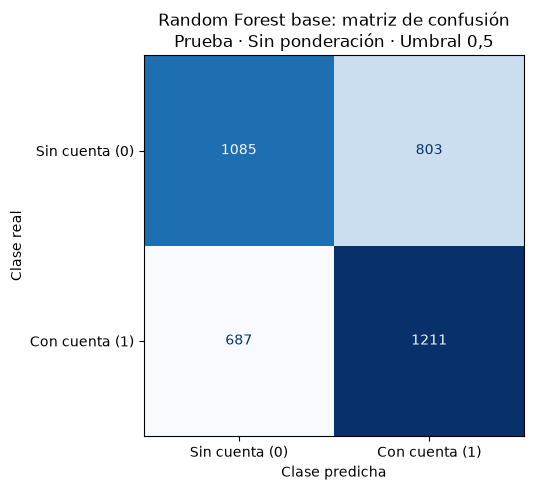

In [6]:
pd.DataFrame(cm, index=["real_sin_cuenta", "real_con_cuenta"],
             columns=["predicho_sin_cuenta", "predicho_con_cuenta"]).to_csv(
    METRICS / "random_forest_confusion_matrix.csv", index_label="clase_real",
)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=["Sin cuenta (0)", "Con cuenta (1)"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d",
)
ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
ax.set_title("Random Forest base: matriz de confusión\nPrueba · Sin ponderación · Umbral 0,5")
fig.tight_layout(); fig.savefig(FIGURES / "random_forest_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close(fig)

### Curva ROC
Se muestra cada clase como positiva con su probabilidad respectiva. En el caso binario las áreas coinciden al invertir simultáneamente el objetivo y la probabilidad. La línea diagonal representa ausencia de discriminación.

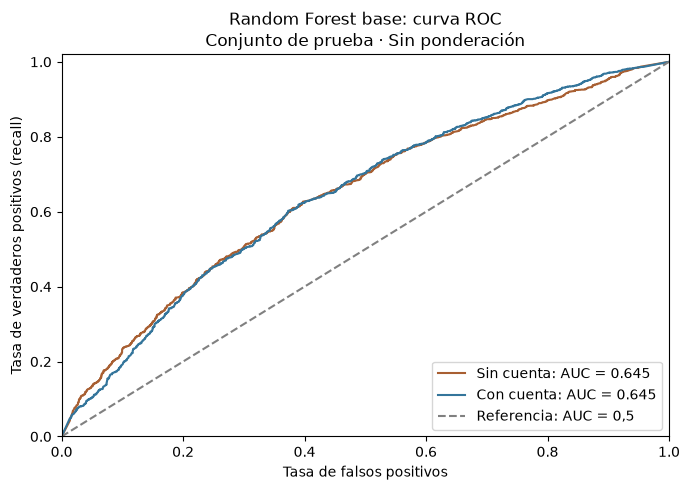

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
roc_tables = []
for label, scores, name, color in [(0, p0, "Sin cuenta", "#a85f32"), (1, p1, "Con cuenta", "#34759b")]:
    fpr, tpr, thresholds = roc_curve(y_test.eq(label), scores)
    auc = float(class_metrics.loc[class_metrics.clase.eq(label), "roc_auc_uno_contra_resto"].iloc[0])
    ax.plot(fpr, tpr, color=color, label=f"{name}: AUC = {auc:.3f}")
    roc_tables.append(pd.DataFrame({"clase_positiva": label, "fpr": fpr, "tpr": tpr, "umbral": thresholds}))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Referencia: AUC = 0,5")
ax.set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos (recall)",
       title="Random Forest base: curva ROC\nConjunto de prueba · Sin ponderación", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(FIGURES / "random_forest_roc_curve.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close(fig)
pd.concat(roc_tables, ignore_index=True).to_csv(METRICS / "random_forest_roc_points.csv", index=False)

## 5. Comparación descriptiva con regresión logística
Se leen los resultados ya guardados; no se reentrena la regresión ni se modifican sus archivos. Se verificó que las observaciones del test y sus objetivos coinciden fila por fila. Las diferencias siguientes corresponden a esta partición y especificaciones base; no constituyen una selección final ni una prueba de superioridad de un modelo.

In [8]:
logistic_global = pd.read_csv(METRICS / "logistic_model_comparison.csv")
logistic_global = logistic_global.loc[logistic_global.modelo.eq("Regresión logística")].iloc[0]
logistic_class = pd.read_csv(METRICS / "logistic_metrics.csv")
logistic_class = logistic_class.loc[logistic_class.modelo.eq("Regresión logística")].set_index("clase")
logistic_detection = pd.read_csv(METRICS / "logistic_sensitivity_specificity.csv").iloc[0]
comparison_rows = []
for metric in ["accuracy", "f1_macro", "roc_auc_clase_1"]:
    comparison_rows.append({"metrica": metric, "regresion_logistica": float(logistic_global[metric]), "random_forest": float(overall[metric])})
for metric in ["precision", "recall", "f1_score"]:
    for label in [0, 1]:
        comparison_rows.append({"metrica": f"{metric}_clase_{label}", "regresion_logistica": float(logistic_class.loc[label, metric]),
                                "random_forest": float(class_metrics.loc[class_metrics.clase.eq(label), metric].iloc[0])})
for metric, value in [("sensibilidad", sensitivity0), ("especificidad", specificity0)]:
    comparison_rows.append({"metrica": metric + "_sin_cuenta", "regresion_logistica": float(logistic_detection[metric]), "random_forest": value})
comparison = pd.DataFrame(comparison_rows)
comparison["diferencia_rf_menos_logistica"] = comparison.random_forest - comparison.regresion_logistica
comparison.to_csv(METRICS / "random_forest_model_comparison.csv", index=False)
display(comparison)
display(Markdown(
    f"En este test, Random Forest presenta accuracy **{overall['accuracy']:.4f}**, frente a **{logistic_global['accuracy']:.4f}** "
    f"de regresión logística; F1 macro **{overall['f1_macro']:.4f}** frente a **{logistic_global['f1_macro']:.4f}**; "
    f"ROC-AUC **{overall['roc_auc_clase_1']:.4f}** frente a **{logistic_global['roc_auc_clase_1']:.4f}**. "
    f"Su sensibilidad para sin cuenta es **{sensitivity0:.4f}**, frente a **{logistic_detection.sensibilidad:.4f}**. "
    "Se registran estas diferencias sin declarar un modelo mejor ni ajustar hiperparámetros con el test."
))

,metrica,regresion_logistica,random_forest,diferencia_rf_menos_logistica
0,accuracy,0.641574,0.606445,-0.035129
1,f1_macro,0.641426,0.606008,-0.035417
2,roc_auc_clase_1,0.698089,0.644661,-0.053428
3,precision_clase_0,0.645799,0.612302,-0.033497
4,precision_clase_1,0.637659,0.601291,-0.036368
5,recall_clase_0,0.622881,0.574682,-0.048199
6,recall_clase_1,0.660169,0.638040,-0.022129
7,f1_score_clase_0,0.634133,0.592896,-0.041237
8,f1_score_clase_1,0.648719,0.619121,-0.029598
9,sensibilidad_sin_cuenta,0.622881,0.574682,-0.048199


En este test, Random Forest presenta accuracy **0.6064**, frente a **0.6416** de regresión logística; F1 macro **0.6060** frente a **0.6414**; ROC-AUC **0.6447** frente a **0.6981**. Su sensibilidad para sin cuenta es **0.5747**, frente a **0.6229**. Se registran estas diferencias sin declarar un modelo mejor ni ajustar hiperparámetros con el test.

## 6. Controles y guardado
Se comprueban la correspondencia entre matriz y métricas, el promedio macro, la persistencia de la pipeline y que no se alteren los insumos de la regresión. Se guarda la pipeline completa comprimida y los parámetros efectivos. El dataset y los índices guardados conservan sus huellas.

Limitaciones: esta primera parte evalúa el bosque base. La búsqueda con validación cruzada se presenta a continuación. La partición aleatoria describe personas de la mezcla de economías cubierta; no estima generalización a economías nuevas ni estabilidad temporal. Las métricas son muestrales y sin ponderación; no representan tasas poblacionales regionales. Los resultados predictivos no demuestran causalidad. No se modifica el notebook de comparación final.

In [9]:
assert cm.sum() == len(y_test)
assert np.isclose(np.trace(cm) / cm.sum(), overall["accuracy"])
assert np.isclose(overall["f1_macro"], class_metrics.f1_score.mean())
assert np.isclose(sensitivity0, class_metrics.loc[class_metrics.clase.eq(0), "recall"].iloc[0])
assert np.isclose(specificity0, class_metrics.loc[class_metrics.clase.eq(1), "recall"].iloc[0])
assert np.isclose(class_metrics.roc_auc_uno_contra_resto.iloc[0], class_metrics.roc_auc_uno_contra_resto.iloc[1])
model_path = MODELS / "random_forest_base.joblib"
joblib.dump(random_forest, model_path, compress=3)
restored = joblib.load(model_path)
assert np.array_equal(restored.predict(X_test), y_pred)
assert np.allclose(restored.predict_proba(X_test), probabilities)
assert all(sha256(ROOT / name) == value for name, value in input_hashes.items())
artifact_paths = [METRICS / name for name in [
    "random_forest_split_summary.csv", "random_forest_overall_metrics.csv", "random_forest_metrics.csv",
    "random_forest_sensitivity_specificity.csv", "random_forest_test_predictions.csv",
    "random_forest_confusion_matrix.csv", "random_forest_roc_points.csv", "random_forest_model_comparison.csv",
]] + [FIGURES / "random_forest_confusion_matrix.png", FIGURES / "random_forest_roc_curve.png"]
assert all(path.is_file() and path.stat().st_size > 0 for path in artifact_paths)
run_info = {
    "dataset": "data/processed/findex_lac_clean.csv", "dataset_sha256": input_hashes["data/processed/findex_lac_clean.csv"],
    "split": "outputs/tables/model_split_indices.csv", "input_sha256": input_hashes,
    "predictors": predictors, "target": "account_fin", "n_train": len(y_train), "n_test": len(y_test),
    "weighting": "Sin ponderación muestral ni de clases", "model_parameters": forest.get_params(),
    "preprocessing": "Edad centrada en train; OneHot con mismas categorías/referencias que regresión logística",
    "age_training_mean": float(age_transformer.mean_[0]), "features": transformer.get_feature_names_out().tolist(),
    "threshold_class_1": "P(account_fin=1) > 0.5", "positive_class_for_detection": 0,
    "python": sys.version.split()[0],
    "packages": {name: importlib.metadata.version(name) for name in ["pandas", "numpy", "scikit-learn", "matplotlib", "joblib"]},
    "artifact_sha256": {str(path.relative_to(ROOT)): sha256(path) for path in artifact_paths},
    "model_file": str(model_path.relative_to(ROOT)),
    "checks": "Sin faltantes; mismos índices y orden train/test; pipeline solo train; métricas y matriz coherentes; pipeline recargada; insumos intactos",
}
(METRICS / "random_forest_run_info.json").write_text(json.dumps(run_info, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("Controles correctos. Modelo, métricas y figuras guardados con prefijo random_forest_.")
print("No se modificaron el dataset, la partición ni los resultados de regresión logística.")

Controles correctos. Modelo, métricas y figuras guardados con prefijo random_forest_.
No se modificaron el dataset, la partición ni los resultados de regresión logística.


## 7. Búsqueda de hiperparámetros solo en entrenamiento
Se fija el espacio siguiente antes de evaluar el bosque ajustado. Se usa [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html) con **16 configuraciones**, semilla 42 y **5 folds estratificados** (`shuffle=True`, semilla 42): 80 ajustes de validación. Esta búsqueda explora una muestra reproducible de 540 combinaciones; no pretende ser exhaustiva.

| Parámetro | Valores considerados |
|---|---|
| n_estimators | 100, 200, 300 |
| max_depth | 4, 6, 8, 12, sin límite |
| min_samples_split | 2, 10, 30 |
| min_samples_leaf | 1, 5, 15, 30 |
| max_features | sqrt, 0.5, 1.0 |

`max_features` se aplica a las diez características después del One-Hot. Se clona la pipeline base completa y se reajusta el preprocesamiento dentro de cada fold. Solo se pasan **X_train e y_train (15.141 filas)** a la búsqueda, nunca el test ni el dataset completo. Los folds usan el mismo orden de entrenamiento y semilla empleados en la validación logística.

**Criterio de selección: mayor media de ROC-AUC en CV.** F1 macro se reporta como métrica adicional y no interviene en la selección. Los empates en ROC-AUC se resuelven por el primer candidato seleccionado por la búsqueda, sin consultar el test. No se ajustan umbral, pesos ni país. Se utilizan dos procesos para candidatos/folds y el bosque mantiene su paralelismo predeterminado, evitando paralelismo anidado.

Con `refit="roc_auc"`, la búsqueda reajusta automáticamente la configuración seleccionada sobre todo el entrenamiento. Los desvíos `std_test_*` de scikit-learn en la tabla completa usan ddof=0; el resumen de los cinco folds de la configuración elegida usa la desviación muestral ddof=1 para facilitar comparación con la validación anterior. Las medias CV de la configuración seleccionada pueden ser optimistas por la selección entre candidatos; no equivalen a validación anidada.

In [10]:
parameter_space = {
    "modelo__n_estimators": [100, 200, 300],
    "modelo__max_depth": [4, 6, 8, 12, None],
    "modelo__min_samples_split": [2, 10, 30],
    "modelo__min_samples_leaf": [1, 5, 15, 30],
    "modelo__max_features": ["sqrt", 0.5, 1.0],
}
tuning_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tuning_folds = list(tuning_cv.split(X_train, y_train))
validation_positions = np.concatenate([validation for _, validation in tuning_folds])
assert np.array_equal(np.sort(validation_positions), np.arange(len(X_train)))
for fit_positions, validation_positions_fold in tuning_folds:
    assert not set(fit_positions).intersection(validation_positions_fold)
    assert set(X_train.iloc[fit_positions].index).isdisjoint(X_test.index)
    assert set(X_train.iloc[validation_positions_fold].index).isdisjoint(X_test.index)
    assert set(y_train.iloc[validation_positions_fold].unique()) == {0, 1}

search = RandomizedSearchCV(
    estimator=clone(random_forest), param_distributions=parameter_space, n_iter=16,
    scoring={"roc_auc": "roc_auc", "f1_macro": "f1_macro"}, refit="roc_auc",
    cv=tuning_folds, random_state=42, n_jobs=2, pre_dispatch=2,
    error_score="raise", return_train_score=False, verbose=1,
)
search.fit(X_train, y_train)
assert search.n_splits_ == 5 and len(search.cv_results_["params"]) == 16
assert np.isfinite(search.cv_results_["mean_test_roc_auc"]).all()
assert np.isfinite(search.cv_results_["mean_test_f1_macro"]).all()
assert np.isclose(search.best_score_, np.max(search.cv_results_["mean_test_roc_auc"]))
tuned_pipeline = search.best_estimator_  # Ya ajustada con las 15.141 filas por refit.
tuned_forest = tuned_pipeline.named_steps["modelo"]
tuned_preprocessing = tuned_pipeline.named_steps["preprocesamiento"]
tuned_age = tuned_preprocessing.named_transformers_["edad"]
assert int(tuned_age.n_samples_seen_) == len(X_train)
assert np.isclose(tuned_age.mean_[0], X_train.age.mean())
assert np.array_equal(tuned_preprocessing.get_feature_names_out(), transformer.get_feature_names_out())
assert tuned_forest.random_state == 42
assert tuned_forest.classes_.tolist() == [0, 1]
print("Configuración elegida exclusivamente por ROC-AUC CV:", search.best_params_)

Fitting 5 folds for each of 16 candidates, totalling 80 fits


Configuración elegida exclusivamente por ROC-AUC CV: {'modelo__n_estimators': 300, 'modelo__min_samples_split': 2, 'modelo__min_samples_leaf': 15, 'modelo__max_features': 0.5, 'modelo__max_depth': 8}


In [11]:
cv_results = pd.DataFrame(search.cv_results_)
cv_results.insert(0, "candidato", np.arange(1, len(cv_results) + 1))
cv_results["seleccionado"] = cv_results.index == search.best_index_
cv_results.to_csv(METRICS / "random_forest_tuned_cv_results.csv", index=False)
display(cv_results.sort_values("rank_test_roc_auc")[[
    "candidato", "seleccionado", "param_modelo__n_estimators", "param_modelo__max_depth",
    "param_modelo__min_samples_split", "param_modelo__min_samples_leaf", "param_modelo__max_features",
    "mean_test_roc_auc", "std_test_roc_auc", "mean_test_f1_macro", "std_test_f1_macro",
]])
best_index = search.best_index_
best_cv_folds = pd.DataFrame({
    "fold": np.arange(1, 6),
    "n_ajuste": [len(fit) for fit, _ in tuning_folds],
    "n_validacion": [len(validation) for _, validation in tuning_folds],
    "roc_auc": [search.cv_results_[f"split{i}_test_roc_auc"][best_index] for i in range(5)],
    "f1_macro": [search.cv_results_[f"split{i}_test_f1_macro"][best_index] for i in range(5)],
})
best_cv_folds.to_csv(METRICS / "random_forest_tuned_best_cv_folds.csv", index=False)
best_cv_summary = pd.DataFrame({
    "metrica": ["roc_auc", "f1_macro"],
    "media": best_cv_folds[["roc_auc", "f1_macro"]].mean().values,
    "desviacion_estandar_ddof1": best_cv_folds[["roc_auc", "f1_macro"]].std(ddof=1).values,
})
best_cv_summary.to_csv(METRICS / "random_forest_tuned_cv_summary.csv", index=False)
(METRICS / "random_forest_tuned_best_params.json").write_text(
    json.dumps({"best_params": search.best_params_, "selection_metric": "roc_auc",
                "best_cv_roc_auc": float(search.best_score_), "best_candidate": int(best_index + 1),
                "n_candidates": 16, "n_splits": 5, "random_state": 42,
                "n_training_refit": len(X_train)}, ensure_ascii=False, indent=2) + "\n", encoding="utf-8",
)
display(best_cv_folds)
display(best_cv_summary)

,candidato,seleccionado,param_modelo__n_estimators,param_modelo__max_depth,param_modelo__min_samples_split,param_modelo__min_samples_leaf,param_modelo__max_features,mean_test_roc_auc,std_test_roc_auc,mean_test_f1_macro,std_test_f1_macro
14,15,True,300,8,2,15,0.5,0.710137,0.004575,0.650972,0.005508
11,12,False,100,6,2,5,sqrt,0.708689,0.004438,0.653498,0.003130
0,1,False,200,8,10,5,sqrt,0.708201,0.004306,0.650082,0.006089
15,16,False,100,6,30,5,1.0,0.707892,0.005311,0.651427,0.003279
6,7,False,100,8,2,5,1.0,0.705915,0.004687,0.648615,0.006786
10,11,False,100,4,30,1,sqrt,0.704638,0.004288,0.649555,0.003498
8,9,False,100,12,2,15,sqrt,0.704014,0.005351,0.649774,0.005111
9,10,False,300,12,10,15,0.5,0.703994,0.005433,0.650642,0.003402
3,4,False,300,4,10,5,1.0,0.701073,0.004483,0.636815,0.008836
5,6,False,300,4,10,1,1.0,0.701063,0.004474,0.636759,0.008747


,fold,n_ajuste,n_validacion,roc_auc,f1_macro
0,1,12112,3029,0.714830,0.657367
1,2,12113,3028,0.714008,0.654164
2,3,12113,3028,0.710135,0.654552
3,4,12113,3028,0.701919,0.643654
4,5,12113,3028,0.709794,0.645121


,metrica,media,desviacion_estandar_ddof1
0,roc_auc,0.710137,0.005115
1,f1_macro,0.650972,0.006158


## 8. Evaluación única del bosque ajustado en el test
Una vez fijada la configuración mediante CV y realizado el refit, se obtiene **una sola vez** la matriz de probabilidades sobre las 3.786 personas de prueba. Las etiquetas se derivan de esas mismas probabilidades, respetando la regla de Random Forest: mayor probabilidad y, en empate, clase 0. Todos los gráficos y métricas reutilizan estas predicciones guardadas. No se prueba otra configuración ni se ajusta el umbral después de este paso.

Las métricas son sin ponderación muestral. Para sensibilidad y especificidad se considera positiva la clase **sin cuenta (0)**; ROC-AUC utiliza la probabilidad de con cuenta (1), con la inversión correspondiente para evaluar la clase 0.

In [12]:
# Única inferencia sobre test de la configuración ajustada; se reutilizan sus resultados.
tuned_probabilities = tuned_pipeline.predict_proba(X_test)
tuned_p1 = tuned_probabilities[:, list(tuned_forest.classes_).index(1)]
tuned_p0 = tuned_probabilities[:, list(tuned_forest.classes_).index(0)]
tuned_pred = tuned_forest.classes_[np.argmax(tuned_probabilities, axis=1)]
assert np.allclose(tuned_p0 + tuned_p1, 1)
assert np.array_equal(tuned_pred, (tuned_p1 > 0.5).astype(int))
tuned_overall, tuned_class_metrics = evaluate_binary_classifier(
    y_test, tuned_pred, tuned_p1, "Random Forest ajustado",
)
tuned_cm = confusion_matrix(y_test, tuned_pred, labels=[0, 1])
tuned_tp0, tuned_fn0 = int(tuned_cm[0, 0]), int(tuned_cm[0, 1])
tuned_fp0, tuned_tn0 = int(tuned_cm[1, 0]), int(tuned_cm[1, 1])
tuned_sensitivity0 = tuned_tp0 / (tuned_tp0 + tuned_fn0)
tuned_specificity0 = tuned_tn0 / (tuned_tn0 + tuned_fp0)
tuned_overall["sensibilidad_sin_cuenta"] = tuned_sensitivity0
tuned_overall["especificidad_sin_cuenta"] = tuned_specificity0
pd.DataFrame([tuned_overall]).to_csv(METRICS / "random_forest_tuned_overall_metrics.csv", index=False)
tuned_class_metrics.to_csv(METRICS / "random_forest_tuned_metrics.csv", index=False)
pd.DataFrame([{
    "clase_positiva": 0, "etiqueta": "Sin cuenta", "n_prueba": len(y_test),
    "verdaderos_positivos": tuned_tp0, "falsos_negativos": tuned_fn0,
    "falsos_positivos": tuned_fp0, "verdaderos_negativos": tuned_tn0,
    "sensibilidad": tuned_sensitivity0, "especificidad": tuned_specificity0,
}]).to_csv(METRICS / "random_forest_tuned_sensitivity_specificity.csv", index=False)
pd.DataFrame({
    "fila_dataset": X_test.index, "account_fin_real": y_test.to_numpy(),
    "account_fin_predicho": tuned_pred, "prob_sin_cuenta": tuned_p0, "prob_con_cuenta": tuned_p1,
}).to_csv(METRICS / "random_forest_tuned_test_predictions.csv", index=False)
display(pd.DataFrame([tuned_overall]))
display(tuned_class_metrics)
display(Markdown(
    f"La sensibilidad para detectar sin cuenta es **{100 * tuned_sensitivity0:.2f}%** "
    f"({tuned_tp0}/{tuned_tp0 + tuned_fn0}); la especificidad es **{100 * tuned_specificity0:.2f}%** "
    f"({tuned_tn0}/{tuned_tn0 + tuned_fp0}). Se omiten {tuned_fn0} personas sin cuenta "
    f"y se clasifican como sin cuenta {tuned_fp0} personas que realmente tienen cuenta."
))

,modelo,n_prueba,accuracy,roc_auc_clase_1,f1_macro,sensibilidad_sin_cuenta,especificidad_sin_cuenta
0,Random Forest ajustado,3786,0.653196,0.710537,0.653191,0.650953,0.655427


,modelo,clase,etiqueta,precision,recall,f1_score,n_real,roc_auc_uno_contra_resto
0,Random Forest ajustado,0,Sin cuenta,0.652682,0.650953,0.651816,1888,0.710537
1,Random Forest ajustado,1,Con cuenta,0.653705,0.655427,0.654565,1898,0.710537


La sensibilidad para detectar sin cuenta es **65.10%** (1229/1888); la especificidad es **65.54%** (1244/1898). Se omiten 659 personas sin cuenta y se clasifican como sin cuenta 654 personas que realmente tienen cuenta.

## 9. Matriz de confusión y curva ROC del bosque ajustado
Se conservan el orden sin cuenta (0), con cuenta (1), y las etiquetas en español. Filas de la matriz = clase real; columnas = predicción. Se reutilizan las probabilidades ya calculadas, sin volver a consultar el modelo sobre el test.

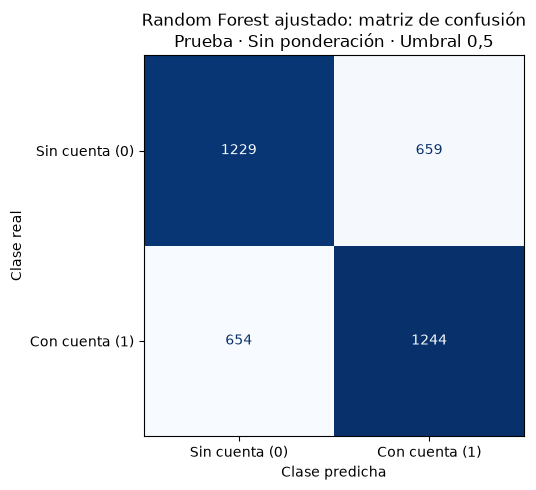

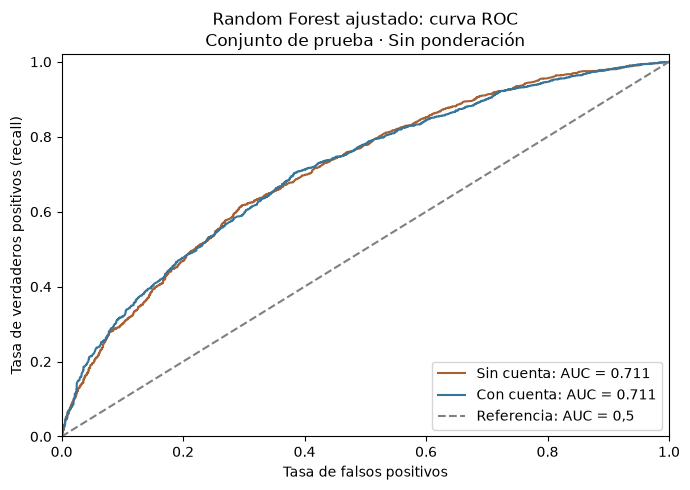

In [13]:
pd.DataFrame(tuned_cm, index=["real_sin_cuenta", "real_con_cuenta"],
             columns=["predicho_sin_cuenta", "predicho_con_cuenta"]).to_csv(
    METRICS / "random_forest_tuned_confusion_matrix.csv", index_label="clase_real",
)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(tuned_cm, display_labels=["Sin cuenta (0)", "Con cuenta (1)"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d",
)
ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
ax.set_title("Random Forest ajustado: matriz de confusión\nPrueba · Sin ponderación · Umbral 0,5")
fig.tight_layout(); fig.savefig(FIGURES / "random_forest_tuned_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close(fig)
fig, ax = plt.subplots(figsize=(7, 5))
tuned_roc_tables = []
for label, scores, name, color in [(0, tuned_p0, "Sin cuenta", "#a85f32"), (1, tuned_p1, "Con cuenta", "#34759b")]:
    fpr, tpr, thresholds = roc_curve(y_test.eq(label), scores)
    auc = float(tuned_class_metrics.loc[tuned_class_metrics.clase.eq(label), "roc_auc_uno_contra_resto"].iloc[0])
    ax.plot(fpr, tpr, color=color, label=f"{name}: AUC = {auc:.3f}")
    tuned_roc_tables.append(pd.DataFrame({"clase_positiva": label, "fpr": fpr, "tpr": tpr, "umbral": thresholds}))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Referencia: AUC = 0,5")
ax.set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos (recall)",
       title="Random Forest ajustado: curva ROC\nConjunto de prueba · Sin ponderación", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(FIGURES / "random_forest_tuned_roc_curve.png", dpi=150, bbox_inches="tight")
plt.show(); plt.close(fig)
pd.concat(tuned_roc_tables, ignore_index=True).to_csv(METRICS / "random_forest_tuned_roc_points.csv", index=False)

## 10. Comparación descriptiva de las tres especificaciones
Se comparan los resultados de la única configuración seleccionada por CV con el bosque base y la regresión logística sobre las mismas personas de prueba. Las diferencias no se usan para relanzar la búsqueda, modificar el umbral ni declarar un ganador final. El test ya había sido consultado en etapas anteriores, por lo que esta comparación es exploratoria y no equivale a una evaluación externa nueva.

In [14]:
logistic_comparison_row = {
    "modelo": "Regresión logística", "accuracy": float(logistic_global["accuracy"]),
    "f1_macro": float(logistic_global["f1_macro"]), "roc_auc_clase_1": float(logistic_global["roc_auc_clase_1"]),
    "sensibilidad_sin_cuenta": float(logistic_detection.sensibilidad),
    "especificidad_sin_cuenta": float(logistic_detection.especificidad),
}
tuned_comparison = pd.DataFrame([logistic_comparison_row, overall, tuned_overall])
tuned_comparison = tuned_comparison[["modelo", "accuracy", "f1_macro", "roc_auc_clase_1", "sensibilidad_sin_cuenta", "especificidad_sin_cuenta"]]
tuned_comparison.to_csv(METRICS / "random_forest_tuned_model_comparison.csv", index=False)
all_class_metrics = pd.concat([
    pd.read_csv(METRICS / "logistic_metrics.csv").query("modelo == 'Regresión logística'"),
    class_metrics, tuned_class_metrics,
], ignore_index=True)
all_class_metrics.to_csv(METRICS / "random_forest_tuned_class_comparison.csv", index=False)
display(tuned_comparison)
display(all_class_metrics)
display(Markdown(
    f"El bosque ajustado registra accuracy **{tuned_overall['accuracy']:.4f}**, F1 macro **{tuned_overall['f1_macro']:.4f}** "
    f"y ROC-AUC **{tuned_overall['roc_auc_clase_1']:.4f}**. Las diferencias respecto del bosque base son "
    f"**{tuned_overall['accuracy'] - overall['accuracy']:+.4f}**, **{tuned_overall['f1_macro'] - overall['f1_macro']:+.4f}** "
    f"y **{tuned_overall['roc_auc_clase_1'] - overall['roc_auc_clase_1']:+.4f}**, respectivamente. "
    "Se registran las tres especificaciones sin elegir todavía un ganador final ni atribuir causalidad."
))

,modelo,accuracy,f1_macro,roc_auc_clase_1,sensibilidad_sin_cuenta,especificidad_sin_cuenta
0,Regresión logística,0.641574,0.641426,0.698089,0.622881,0.660169
1,Random Forest base,0.606445,0.606008,0.644661,0.574682,0.638040
2,Random Forest ajustado,0.653196,0.653191,0.710537,0.650953,0.655427


,modelo,clase,etiqueta,precision,recall,f1_score,n_real,roc_auc_uno_contra_resto
0,Regresión logística,0,Sin cuenta,0.645799,0.622881,0.634133,1888,0.698089
1,Regresión logística,1,Con cuenta,0.637659,0.660169,0.648719,1898,0.698089
2,Random Forest base,0,Sin cuenta,0.612302,0.574682,0.592896,1888,0.644661
3,Random Forest base,1,Con cuenta,0.601291,0.638040,0.619121,1898,0.644661
4,Random Forest ajustado,0,Sin cuenta,0.652682,0.650953,0.651816,1888,0.710537
5,Random Forest ajustado,1,Con cuenta,0.653705,0.655427,0.654565,1898,0.710537


El bosque ajustado registra accuracy **0.6532**, F1 macro **0.6532** y ROC-AUC **0.7105**. Las diferencias respecto del bosque base son **+0.0468**, **+0.0472** y **+0.0659**, respectivamente. Se registran las tres especificaciones sin elegir todavía un ganador final ni atribuir causalidad.

## 11. Guardado del modelo ajustado y verificaciones
Se guarda la pipeline completa en `models/random_forest_tuned.joblib`, ya reajustada por la búsqueda con todo el entrenamiento. Para comprobar la persistencia se utilizan cinco filas de entrenamiento; **no se realiza una segunda inferencia en test**. Los controles de métricas y figuras usan las predicciones almacenadas. Se documentan el espacio explorado, la configuración seleccionada, el ajuste completo y las huellas de entradas y salidas.

No se añadió país, no se cambió el split y no se entrenó otro tipo de modelo. Este ajuste moderado no es exhaustivo; las medias CV del candidato seleccionado están sujetas a sesgo de selección y su dispersión no es un intervalo de confianza. El país omitido, la falta de ponderación y la cobertura geográfica siguen limitando la interpretación. La estabilidad frente a otras economías o periodos no se ha evaluado.

In [15]:
assert tuned_cm.sum() == len(y_test)
assert np.isclose(np.trace(tuned_cm) / tuned_cm.sum(), tuned_overall["accuracy"])
assert np.isclose(tuned_class_metrics.f1_score.mean(), tuned_overall["f1_macro"])
assert np.isclose(tuned_sensitivity0, tuned_class_metrics.loc[tuned_class_metrics.clase.eq(0), "recall"].iloc[0])
assert np.isclose(tuned_specificity0, tuned_class_metrics.loc[tuned_class_metrics.clase.eq(1), "recall"].iloc[0])
assert np.isclose(best_cv_folds.roc_auc.mean(), search.best_score_)
assert np.isclose(best_cv_folds.f1_macro.mean(), search.cv_results_["mean_test_f1_macro"][best_index])
assert len(X_train) == 15141 and len(X_test) == 3786
assert all(sha256(ROOT / name) == value for name, value in input_hashes.items())
tuned_model_path = MODELS / "random_forest_tuned.joblib"
joblib.dump(tuned_pipeline, tuned_model_path, compress=3)
restored_tuned = joblib.load(tuned_model_path)
# Persistencia comprobada con entrenamiento, sin nuevas predicciones en test.
assert np.allclose(restored_tuned.predict_proba(X_train.iloc[:5]), tuned_pipeline.predict_proba(X_train.iloc[:5]))
tuned_artifacts = sorted(METRICS.glob("random_forest_tuned_*.csv")) + [
    METRICS / "random_forest_tuned_best_params.json",
    FIGURES / "random_forest_tuned_confusion_matrix.png", FIGURES / "random_forest_tuned_roc_curve.png",
]
tuned_run_info = {
    "dataset": "data/processed/findex_lac_clean.csv", "dataset_sha256": sha256(DATA_PATH),
    "split": "outputs/tables/model_split_indices.csv", "split_sha256": sha256(SPLIT_PATH),
    "predictors": predictors, "n_train": len(X_train), "n_test": len(X_test),
    "search": {"type": "RandomizedSearchCV", "n_iter": 16, "n_splits": 5, "shuffle": True,
               "random_state": 42, "scoring": ["roc_auc", "f1_macro"], "refit": "roc_auc",
               "parameter_space": parameter_space, "n_jobs": 2, "train_only": True},
    "best_params": search.best_params_, "model_parameters": tuned_forest.get_params(),
    "best_cv_summary_ddof1": best_cv_summary.to_dict("records"),
    "selection_uses_test": False, "tuned_test_inference_calls": 1,
    "test_threshold": "P(account_fin=1)>0.5; empates clase 0", "weighting": "Sin ponderación",
    "model_path": str(tuned_model_path.relative_to(ROOT)),
    "artifact_sha256": {str(path.relative_to(ROOT)): sha256(path) for path in tuned_artifacts},
    "packages": run_info["packages"], "python": sys.version.split()[0],
}
(METRICS / "random_forest_tuned_run_info.json").write_text(json.dumps(tuned_run_info, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("Búsqueda: 16 candidatos × 5 folds, solo en entrenamiento. Refit: 15.141 personas.")
print("Configuración elegida evaluada una sola vez en 3.786 personas de prueba.")
print("Pipeline guardada en models/random_forest_tuned.joblib; sin país ni selección final de ganador.")

Búsqueda: 16 candidatos × 5 folds, solo en entrenamiento. Refit: 15.141 personas.
Configuración elegida evaluada una sola vez en 3.786 personas de prueba.
Pipeline guardada en models/random_forest_tuned.joblib; sin país ni selección final de ganador.
